## Colab Notebook created for ARAP module at UPC ETSETB.

Authors: Juan José Nieto, Margarita Cabrera-Bean, Josep Vidal

# WINDY GRID WORLD
[Open to access description of tasks](https://drive.google.com/file/d/1LeB_H2GIxa3dnJqKx-_iWaE8ZZHaA5l4/view?usp=drive_link)

1. Complete the code for each algorithm (Sarsa, Q-Learning, Expected Sarsa and Double Q-Learning).
2. Modify the environment creatively following the description of tasks document


In [ ]:
import numpy as np
import seaborn as sns

from random import random, randint
import matplotlib.pyplot as plt
algs = ['SARSA', 'Q-LEARNING', 'EXPECTED SARSA', 'DOUBLE Q-LEARNING']

In [ ]:
class GridWorld():
    def __init__(self):
        self.N_ROWS = 10
        self.N_COLUMNS = 10
        self.N_STATES = self.N_ROWS * self.N_COLUMNS

        # Define parameters
        self.GAMMA = 1
        self.ALPHA = 0.1
        self.EPSILON = 0.1
        self.N_EPISODES = 2000
        self.G_MIN = -19
        self.N_AV = 5
        self.G = 0

        # left/down/right/up action
        self.ACTIONS = [(0, -1), (1, 0), (0, 1), (-1, 0)]

        self.N_ACTIONS = len(self.ACTIONS)

        # Define inital and final state
        self.INI_STATE = 6
        self.FIN_STATE = 76

        # Define wind for each row and column
        self.WIND_V = [0, 0, 0, -1, -1, -1, -2, -2, -1, 0]
        self.WIND_H = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

        # Define action-value function
        self.Q_FUN = np.zeros((self.N_STATES, self.N_ACTIONS))
        # Define second action-value function for double q-learning
        self.Q_FUN2 = np.zeros((self.N_STATES, self.N_ACTIONS))
        # Define state-value function only for plotting purposes
        self.V_FUN = np.zeros(self.N_STATES)


    ''' Convert state s from scalar to coordinates x,y '''
    def get_XY(self, state):
        return (state % self.N_ROWS, int(state / self.N_ROWS))

    ''' Convert coordinates x,y to scalar state '''
    def get_state(self, state):
        return state[1]*self.N_COLUMNS + state[0]


    '''
    Computes next state and reward

    Params:
        - int: state in {0,..., N_STATES-1}
    Returns:
        - int: next_state in {0,..., N_STATES-1}
        - int: reward
    '''
    def next_position(self, state, action):

        (x,y) = self.get_XY(state)
        # x is the row number and y is the column number
        (ax, ay) = self.ACTIONS[action]

        row = max(0, x + ax + self.WIND_V[y])
        row = min(self.N_ROWS-1, row)
        col = max(0, y + ay + self.WIND_H[x])
        col = min(self.N_COLUMNS-1, col)

        next_state = (row, col)

        next_state = self.get_state(next_state)

        if next_state == self.FIN_STATE:
            return next_state, 0
        return next_state, -1

    '''
    Performs greedy policy. With prob epsilon pick action
    belonging to maximum action-value. With prob 1-epsilon
    pick a random action.

    Params:
        - int: state in {0,..., N_STATES-1}
        - bool: double, indicates whether we are using double q-learning or not
    Returns:
        - int: action in {0,..., N_ACTIONS-1}
    '''
    def greedy_policy(self, state, double=False):

        action = np.argmax(self.Q_FUN[state])
        if double:
            action = np.argmax(self.Q_FUN[state] + self.Q_FUN2[state])

        if random() < self.EPSILON:
            action = randint(0, self.N_ACTIONS - 1)

        return action

    '''
    Compute state-value function

    Returns:
        - list: V_FUN
    '''
    def compute_v_fun(self):
        for i, action_values in enumerate(self.Q_FUN):
            self.V_FUN[i] = np.max(self.Q_FUN[i] + self.Q_FUN2[i])  # QFUN2[i] will be != 0 only in Double Q-Learning
        return self.V_FUN

    '''
    Compute actions taken in each state.

    Params:
        - boolean: double, indicates whether we are using double q-learning or not
    Returns:
        - list: actions, one for each state
    '''
    def compute_actions(self, double=False):
        actions = []
        for s in range(self.N_STATES):
            if double:
                actions.append(np.argmax(self.Q_FUN[s] + self.Q_FUN2[s]))
            else:
                actions.append(np.argmax(self.Q_FUN[s]))

        return actions

    '''
    The following functions are the different algorithms we will try.
    Basically we do two things:
        1. Compute next_state and next_action
        2. Update action-values (Q_FUN)

    Params:
        - int: state in {0,..., N_STATES-1}
        - int: action in {0,..., N_ACTIONS-1}

    Returns:
        - int: next_state in {0,..., N_STATES-1}
        - int: next_action in {0,..., N_ACTIONS-1}
    '''

    # WARNING: Note that some methods use the input variable: action and others do not

    def sarsa(self, state, action):

        # sarsa uses greedy policy for next action too

        # TODO
        next_state, reward = self.next_position(state, action)
        self.G += reward
        next_action = self.greedy_policy(next_state)
        self.Q_FUN[state, action] += self.ALPHA * (reward + self.GAMMA * self.Q_FUN[next_state, next_action] - self.Q_FUN[state, action])

        #
        return next_state, next_action

    def q_learning(self, state, action):

        # q-learning always pick next_action with maximum action-value (q-value)

        # TODO
        action = self.greedy_policy(state)
        next_state, reward = self.next_position(state, action)
        self.G += reward
        next_action = np.argmax(self.Q_FUN[next_state])
        self.Q_FUN[state, action] += self.ALPHA * (reward + self.GAMMA * self.Q_FUN[next_state, next_action] - self.Q_FUN[state, action])

        #
        return next_state, next_action

    def expected_sarsa(self, state, action):

        # expected sarsa is like q-learning but weighting with epsilon and also taking into account
        # the rest of action-values of that state

        # TODO
        next_state, reward = self.next_position(state, action)
        self.G += reward
        next_action = self.greedy_policy(next_state)
        pi = np.full(self.N_ACTIONS, self.EPSILON / self.N_ACTIONS)
        pi[np.argmax(self.Q_FUN[next_state])] += 1 - self.EPSILON
        expected_q = np.sum(pi * self.Q_FUN[next_state])
        self.Q_FUN[state, action] += self.ALPHA * (reward + self.GAMMA * expected_q - self.Q_FUN[state, action])

        #
        return next_state, next_action

    def double_q_learning(self, state, action):
        # Choose action taking into account both Q_FUNs

        # With 50% we will update Q_FUN or Q_FUN2. In either case, the actual q-value taken when computing the td_target
        # is given by the other Q_FUN, but we use the function we are updating to choose the next_action.

        # TODO
        action = self.greedy_policy(state, double=True)
        next_state, reward = self.next_position(state, action)
        self.G += reward
        if random() < 0.5:
            next_action = np.argmax(self.Q_FUN[next_state])
            self.Q_FUN[state, action] += self.ALPHA * (reward + self.GAMMA * self.Q_FUN2[next_state, next_action] - self.Q_FUN[state, action])
        else:
            next_action = np.argmax(self.Q_FUN2[next_state])
            self.Q_FUN2[state, action] += self.ALPHA * (reward + self.GAMMA * self.Q_FUN[next_state, next_action] - self.Q_FUN2[state, action])

        #
        return next_state, next_action

    def deterministic_policy(self):
        max_steps = 50
        state = self.INI_STATE
        trajectory = np.zeros((self.N_ROWS, self.N_COLUMNS))
        steps = 0
        while not state == self.FIN_STATE and steps < max_steps:
            s = self.get_XY(state)
            trajectory[s[0], s[1]] = 1

            action = np.argmax(self.Q_FUN[state] + self.Q_FUN2[state]) # QFUN2[i] will be != 0 only in Double Q-Learning
            next_state, reward = self.next_position(state, action)
            state = next_state
            steps += 1

        if steps == max_steps:
            steps = 'inf'
        return trajectory, steps


### PLOT FUNCTIONS

In [ ]:
'''Insert title, and axis labels to plots'''
def insert_labels(labels, ax):
    if 'title' in labels:
        ax.set_title(labels['title'])
    if 'xlabel' in labels:
        ax.set_xlabel(labels['xlabel'])
    if 'ylabel' in labels:
	    ax.set_ylabel(labels['ylabel'])

def general_plot(vf_matrix, counts, first_policy, optimal_policy, determ_policy, steps, grid):
    fig, ax = plt.subplots(5, len(vf_matrix), figsize=(20, 20))
    fig.tight_layout(pad=2.5)

    X = np.arange(0, grid.N_ROWS, 1)
    Y = np.arange(0, grid.N_COLUMNS, 1)

    s = 0.5 / grid.N_ROWS
    actions = grid.ACTIONS

    r,t = grid.get_XY(grid.INI_STATE)
    w,e = grid.get_XY(grid.FIN_STATE)

    ini_pad_y = (grid.N_ROWS - r)*2-1
    g_pad_y = (grid.N_ROWS - w)*2-1

    ini_pad_x = t*2+1
    g_pad_x = e*2+1

    ini_pad_x = s*ini_pad_x-s/2
    ini_pad_y = s*ini_pad_y-s/2

    g_pad_x = s*g_pad_x-s/2
    g_pad_y = s*g_pad_y-s/2

    for i, data in enumerate([vf_matrix, counts, first_policy, optimal_policy, determ_policy]):
        for j, d in enumerate(data):
            if i==0:
                sns.heatmap(d, cmap='coolwarm', ax=ax[i, j])
                conf = {'title': '{} VALUE FUNCTION'.format(algs[j])}
                insert_labels(conf, ax[i, j])
            elif i==1:
                conf= {
                    'title': 'Number of steps in each episode',
                    'xlabel': 'Episode #',
                    'ylabel': 'number of steps'
                }
                ax[i,j].plot(d)
                insert_labels(conf, ax[i, j])
            elif i==2 or i==3:
                U = np.array([[actions[y][0] for y in x] for x in d])
                V = np.array([[actions[y][1] for y in x] for x in d])

                q = ax[i,j].quiver(X, Y, V, U*-1)
                ax[i,j].imshow(d, cmap=plt.cm.Pastel1)

                ax[i,j].axis('off')
                conf= {'title': '{} Policy'.format('First' if i==2 else 'Final')}
                insert_labels(conf, ax[i,j])

            elif i==4:
                U = np.array([[actions[y][0] if determ_policy[j][l,p]==1 else 0 for p,y in enumerate(x)] for l,x in enumerate(optimal_policy[j])])
                V = np.array([[actions[y][1] if determ_policy[j][l,p]==1 else 0 for p,y in enumerate(x)] for l,x in enumerate(optimal_policy[j])])

                q = ax[i,j].quiver(X, Y, V, U*-1, scale=5.3, scale_units='inches')

                ax[i,j].text(ini_pad_x, ini_pad_y, 'INI', fontsize=14, transform=ax[i,j].transAxes)
                ax[i,j].text(g_pad_x, g_pad_y, 'G', fontsize=14, transform=ax[i,j].transAxes)
                ax[i,j].imshow(d, cmap=plt.cm.Pastel1)

                ax[i,j].axis('off')
                conf= {'title': 'Deterministic Policy. # Steps: {}'.format(steps[j])}
                insert_labels(conf, ax[i,j])






# ALGORITHMS:
1 -> SARSA

2 -> Q-LEARNING

3 -> EXPECTED SARSA

4 -> DOUBLE Q-LEARNING

# STANDARD GRID WORLD

In [ ]:

total_counts = []
total_v_funs = []
total_first_p = []
total_final_p = []
total_determ_p = []
total_steps = []

for ALGORITHM in range(1,5):
    grid = GridWorld()
    counts = []
    returns = []
    for i in range(grid.N_EPISODES):
        state = grid.INI_STATE
        action = grid.greedy_policy(state)
        n_count = 0
        grid.G = 0

        while not state == grid.FIN_STATE:

            if ALGORITHM == 1:
                next_state, next_action = grid.sarsa(state, action)
            elif ALGORITHM == 2:
                next_state, next_action = grid.q_learning(state, action)
            elif ALGORITHM == 3:
                next_state, next_action = grid.expected_sarsa(state, action)
            elif ALGORITHM == 4:
                next_state, next_action = grid.double_q_learning(state, action)

            action = next_action
            state = next_state

            n_count += 1
        if i==0:
            first_policy = grid.compute_actions()
        counts.append(n_count)
        returns.append(grid.G)
        if len(returns) >= grid.N_AV and np.mean(returns[-grid.N_AV:]) > grid.G_MIN:
            break

    v_fun = grid.compute_v_fun()
    vf_matrix = np.transpose(np.reshape(v_fun, (grid.N_ROWS, grid.N_COLUMNS)))
    first_action_arrows = np.transpose(np.array(first_policy).reshape(grid.N_ROWS,grid.N_COLUMNS))
    final_policy = grid.compute_actions(double=True)
    final_action_arrows = np.transpose(np.array(final_policy).reshape(grid.N_ROWS,grid.N_COLUMNS))
    determ_policy, steps = grid.deterministic_policy()

    total_v_funs.append(vf_matrix)
    total_counts.append(counts)
    total_first_p.append(first_action_arrows)
    total_final_p.append(final_action_arrows)
    total_determ_p.append(determ_policy)
    total_steps.append(steps)


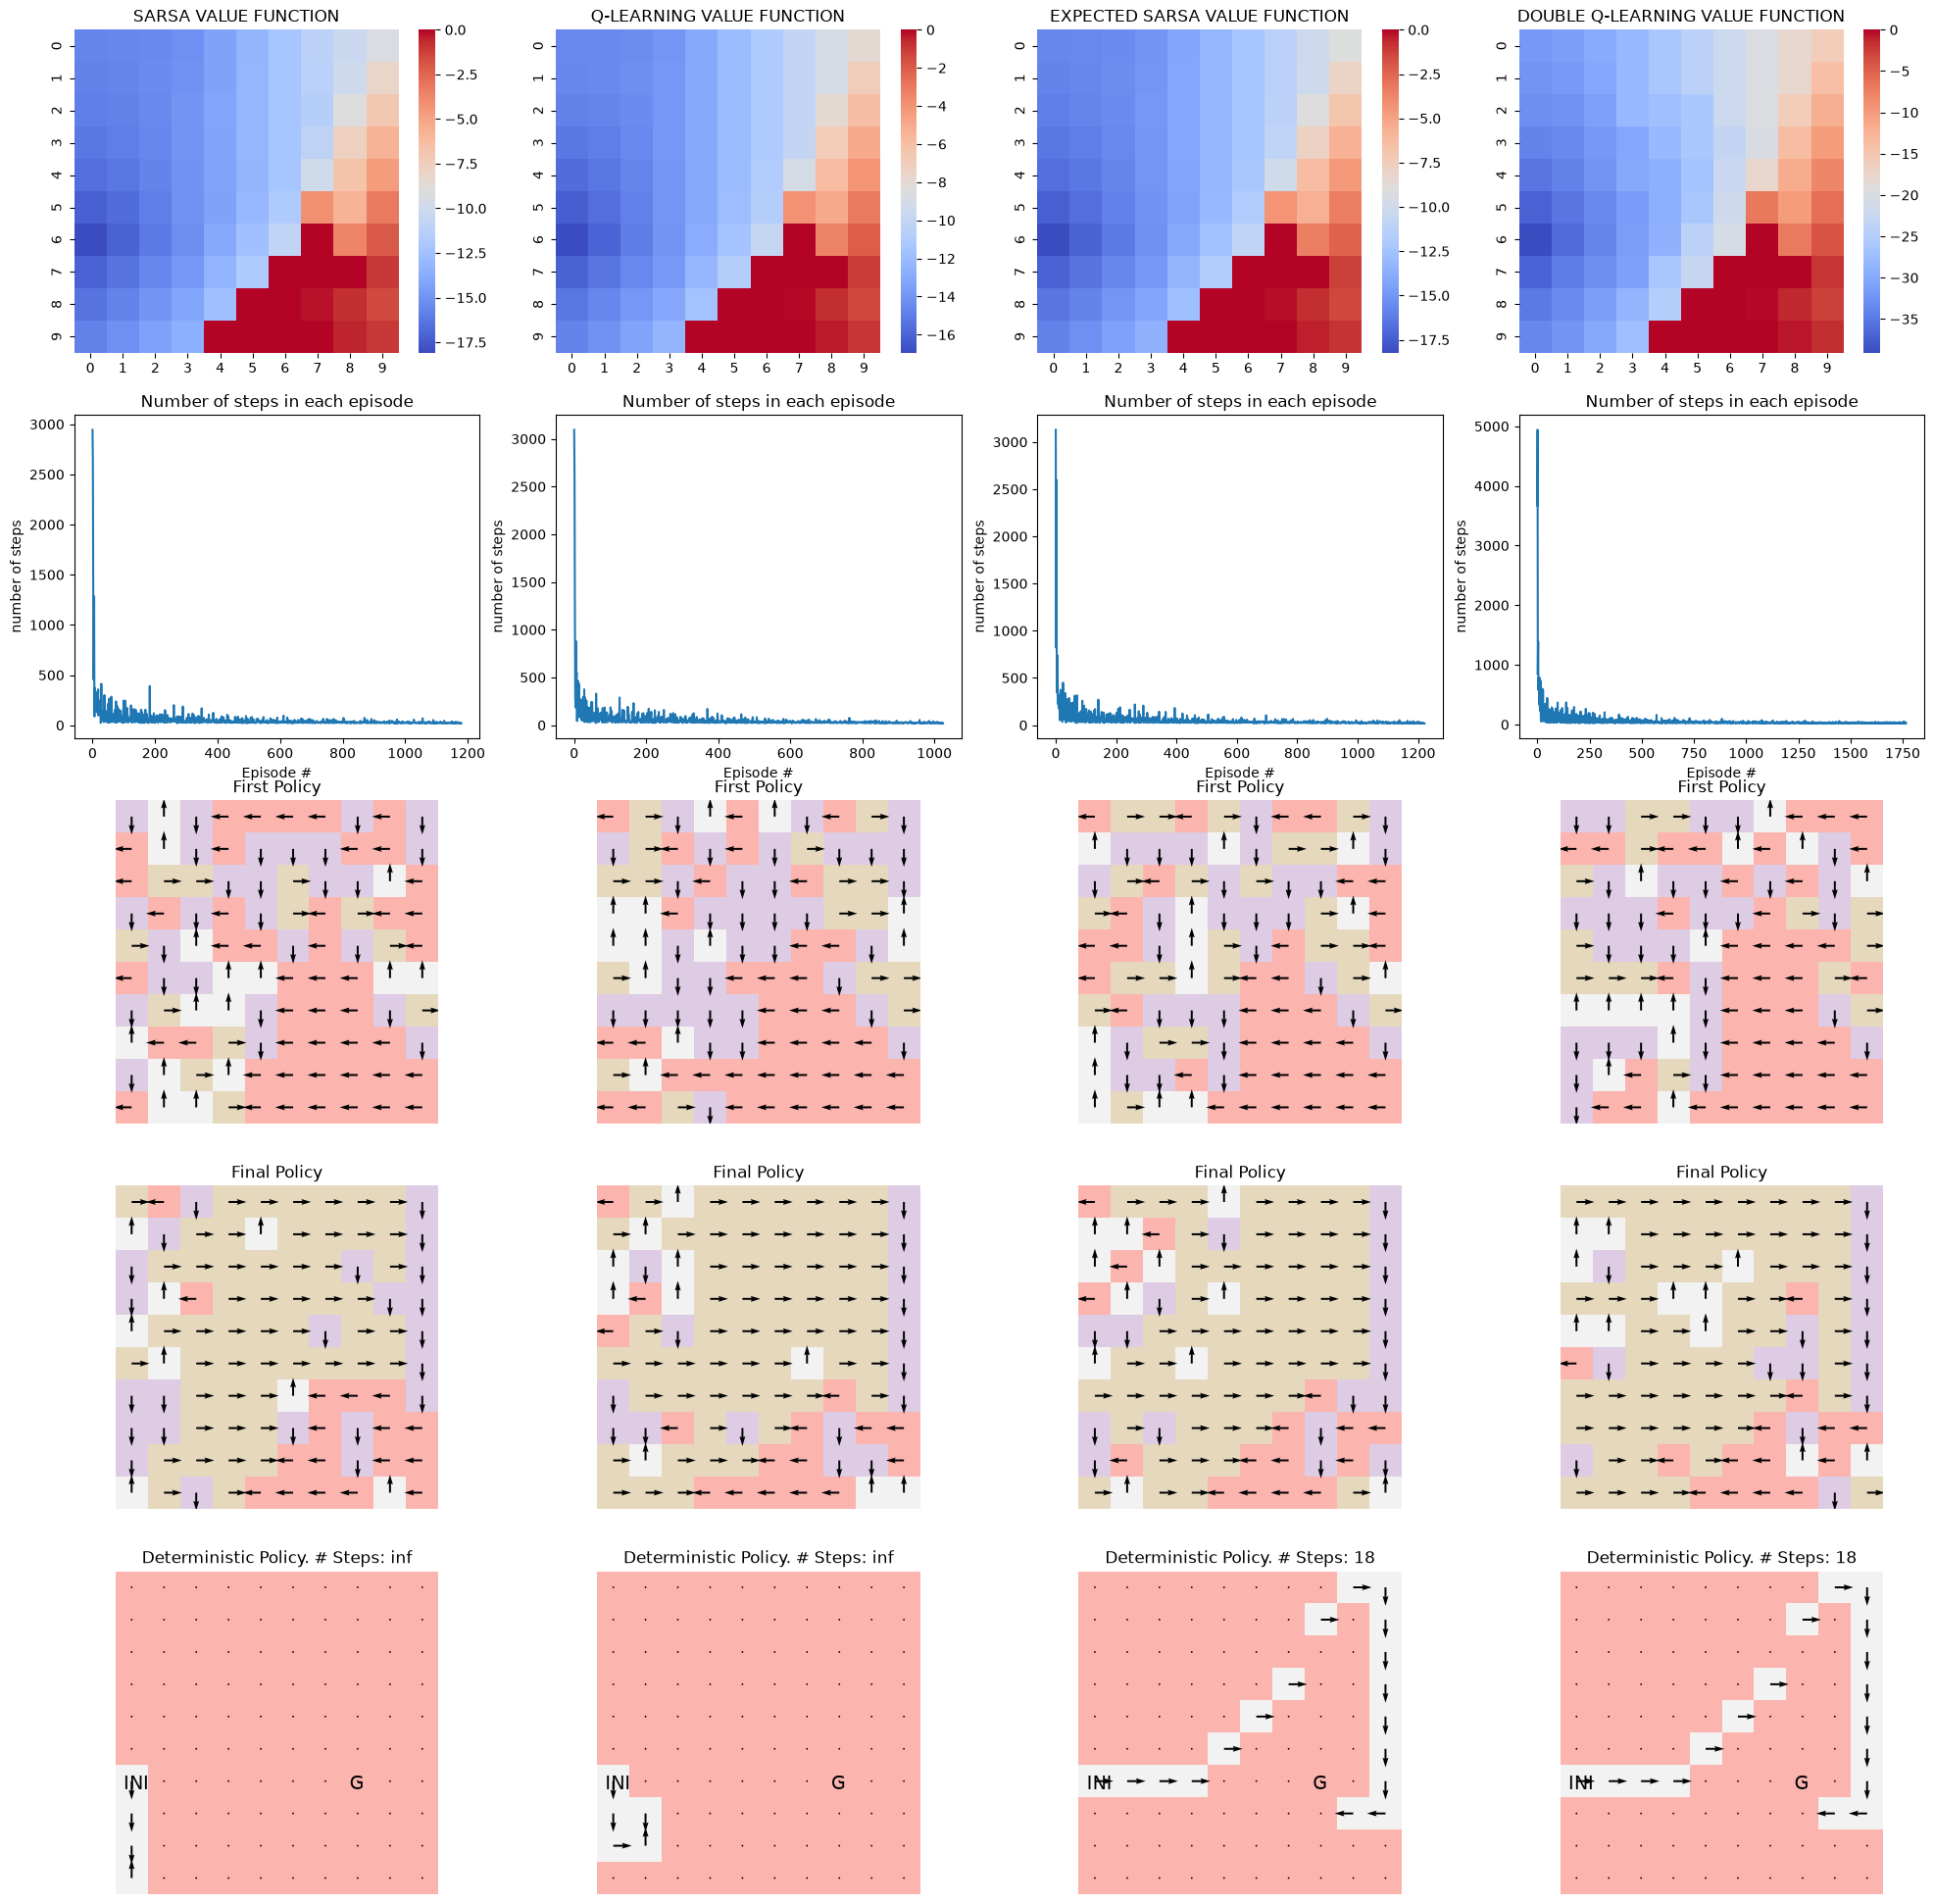

In [ ]:
general_plot(total_v_funs, total_counts, total_first_p, total_final_p, total_determ_p, total_steps, grid)

### 3) Analyze the average number of episodes necessary to get convergence and the average number of steps of the optimal policy obtained.

In [ ]:
from random import seed

def train(ALGORITHM):
    grid = GridWorld()
    td_step = [grid.sarsa, grid.q_learning, grid.expected_sarsa, grid.double_q_learning][ALGORITHM - 1]
    counts = []
    returns = []
    for i in range(grid.N_EPISODES):
        state = grid.INI_STATE
        action = grid.greedy_policy(state)
        n_count = 0
        grid.G = 0
        while not state == grid.FIN_STATE:
            state, action = td_step(state, action)
            n_count += 1
        counts.append(n_count)
        returns.append(grid.G)
        if len(returns) >= grid.N_AV and np.mean(returns[-grid.N_AV:]) > grid.G_MIN:
            break
    return grid, counts

In [ ]:
seed(0)
N_RUNS = 50

for ALGORITHM in range(1, 5):
    episodes = []
    train_steps = []
    greedy_steps = []
    for run in range(N_RUNS):
        grid, counts = train(ALGORITHM)
        trajectory, steps = grid.deterministic_policy()
        episodes.append(len(counts))
        train_steps.append(np.mean(counts[-grid.N_AV:]))
        if steps != 'inf':
            greedy_steps.append(steps)

    print(algs[ALGORITHM - 1])
    print('  average number of episodes to converge:', np.mean(episodes))
    print('  runs that reach N_EPISODES without stopping:', episodes.count(grid.N_EPISODES))
    print('  average steps in the last N_AV episodes:', np.mean(train_steps))
    print('  runs where the greedy policy reaches the goal:', len(greedy_steps), 'of', N_RUNS)
    print('  average steps of the greedy policy in those runs:', np.mean(greedy_steps))
    print('  minimum steps of the greedy policy:', np.min(greedy_steps))

SARSA
  average number of episodes to converge: 1210.94
  runs that reach N_EPISODES without stopping: 0
  average steps in the last N_AV episodes: 19.535999999999998
  runs where the greedy policy reaches the goal: 41 of 50
  average steps of the greedy policy in those runs: 18.829268292682926
  minimum steps of the greedy policy: 18
Q-LEARNING
  average number of episodes to converge: 1015.76
  runs that reach N_EPISODES without stopping: 0
  average steps in the last N_AV episodes: 19.572
  runs where the greedy policy reaches the goal: 37 of 50
  average steps of the greedy policy in those runs: 18.62162162162162
  minimum steps of the greedy policy: 18
EXPECTED SARSA
  average number of episodes to converge: 1198.66
  runs that reach N_EPISODES without stopping: 0
  average steps in the last N_AV episodes: 19.596
  runs where the greedy policy reaches the goal: 37 of 50
  average steps of the greedy policy in those runs: 19.054054054054053
  minimum steps of the greedy policy: 18


In [ ]:
seed(0)
steps = 0
while steps != 'inf':
    grid, counts = train(1)
    trajectory, steps = grid.deterministic_policy()

state = grid.INI_STATE
for t in range(50):
    state, reward = grid.next_position(state, np.argmax(grid.Q_FUN[state]))

print('episodes:', len(counts))
print('steps in the last N_AV episodes:', counts[-grid.N_AV:])
print('greedy path ends in:', grid.get_XY(state))
print('Q values there:', grid.Q_FUN[state])
print('greedy action there:', np.argmax(grid.Q_FUN[state]))

episodes: 1186
steps in the last N_AV episodes: [18, 18, 19, 24, 19]
greedy path ends in: (5, 4)
Q values there: [-14.39518273 -14.28501395 -14.28546626 -14.29393291]
greedy action there: 1


Q-learning converges first, in about $1000$ episodes. Its target uses $\max_a Q(S_{t+1},a)$, so it learns the greedy policy directly and the exploratory actions do not enter the target. SARSA and Expected SARSA need about $1200$ episodes. Their targets follow the $\epsilon$-greedy policy, so the exploratory actions lower the values and the learning is slower. Expected SARSA gives no clear gain over SARSA here since both move in the same direction in expectation. Double Q-learning is the slowest with about $1650$ episodes and $7$ runs that do not stop. Each step updates only one of $Q_1$ and $Q_2$ so each one learns from half of the steps.

The four algorithms obtain the same policy. The shortest path found is $18$ steps in all of them which gives $G(s_{ini}) = -17$. So in the windy grid world the algorithms differ in the number of episodes and not in the policy obtained. During training the episodes take between $19.5$ and $20$ steps and not $18$, because the $\epsilon$-greedy policy takes exploratory actions.

The stopping criterion does not guarantee that $Q$ has converged. It measures $G(s_{ini})$ of the $\epsilon$-greedy episodes where $Q$ is still being updated. With $Q$ fixed, the greedy policy takes about $19$ steps on average and not $18$ and it does not always reach the goal. In the previous print, training has stopped but in one cell next to the path the four $Q$ values are almost equal and the greedy action is down. The wind cancels it, so the agent stays in the same cell.

The recommendation would be Q-learning since it obtains the same path of $18$ steps with the fewest episodes.

### 4) Modify the environment to emulate the cliff grid world. This implies among other things to change GridWorld class and function next_position.

In [ ]:
class CliffGridWorld(GridWorld):
    def __init__(self):
        super().__init__()
        self.N_ROWS = 5
        self.N_COLUMNS = 5
        self.N_STATES = self.N_ROWS * self.N_COLUMNS

        self.INI_STATE = self.get_state((3, 0))
        self.FIN_STATE = self.get_state((2, 4))

        self.FORBIDDEN = [(1, 1), (1, 2), (1, 3), (2, 1), (2, 2), (2, 3)]
        self.CLIFF_ROW = 4

        self.Q_FUN = np.zeros((self.N_STATES, self.N_ACTIONS))
        self.Q_FUN2 = np.zeros((self.N_STATES, self.N_ACTIONS))
        self.V_FUN = np.zeros(self.N_STATES)

    def next_position(self, state, action):

        (x,y) = self.get_XY(state)
        (ax, ay) = self.ACTIONS[action]

        row = max(0, x + ax)
        row = min(self.N_ROWS-1, row)
        col = max(0, y + ay)
        col = min(self.N_COLUMNS-1, col)

        if (row, col) in self.FORBIDDEN:
            (row, col) = (x, y)

        if row == self.CLIFF_ROW:
            return self.INI_STATE, -100
        return self.get_state((row, col)), -1

### 5) Test the algorithms SARSA, Expected-SARSA, Q-learning and Double Q-Learning on the Cliff problem.

In [ ]:
seed(0)

total_counts = []
total_returns = []
total_v_funs = []
total_first_p = []
total_final_p = []
total_determ_p = []
total_steps = []

for ALGORITHM in range(1,5):
    grid = CliffGridWorld()
    counts = []
    returns = []
    for i in range(grid.N_EPISODES):
        state = grid.INI_STATE
        action = grid.greedy_policy(state)
        n_count = 0
        grid.G = 0

        while not state == grid.FIN_STATE:

            if ALGORITHM == 1:
                next_state, next_action = grid.sarsa(state, action)
            elif ALGORITHM == 2:
                next_state, next_action = grid.q_learning(state, action)
            elif ALGORITHM == 3:
                next_state, next_action = grid.expected_sarsa(state, action)
            elif ALGORITHM == 4:
                next_state, next_action = grid.double_q_learning(state, action)

            action = next_action
            state = next_state

            n_count += 1
        if i==0:
            first_policy = grid.compute_actions()
        counts.append(n_count)
        returns.append(grid.G)

    v_fun = grid.compute_v_fun()
    vf_matrix = np.transpose(np.reshape(v_fun, (grid.N_ROWS, grid.N_COLUMNS)))
    first_action_arrows = np.transpose(np.array(first_policy).reshape(grid.N_ROWS,grid.N_COLUMNS))
    final_policy = grid.compute_actions(double=True)
    final_action_arrows = np.transpose(np.array(final_policy).reshape(grid.N_ROWS,grid.N_COLUMNS))
    determ_policy, steps = grid.deterministic_policy()

    total_v_funs.append(vf_matrix)
    total_counts.append(counts)
    total_returns.append(returns)
    total_first_p.append(first_action_arrows)
    total_final_p.append(final_action_arrows)
    total_determ_p.append(determ_policy)
    total_steps.append(steps)

    print(algs[ALGORITHM - 1])
    print('  steps of the greedy policy:', steps)
    print('  average G(s_ini) over the', grid.N_EPISODES, 'episodes:', np.mean(returns))
    print('  average G(s_ini) in the last 100 episodes:', np.mean(returns[-100:]))
    print('  episodes with a fall into the cliff:', np.sum(np.array(returns) <= -100))

SARSA
  steps of the greedy policy: 9
  average G(s_ini) over the 2000 episodes: -14.846
  average G(s_ini) in the last 100 episodes: -12.69
  episodes with a fall into the cliff: 76
Q-LEARNING
  steps of the greedy policy: 5
  average G(s_ini) over the 2000 episodes: -19.343
  average G(s_ini) in the last 100 episodes: -19.67
  episodes with a fall into the cliff: 234
EXPECTED SARSA
  steps of the greedy policy: 9
  average G(s_ini) over the 2000 episodes: -14.621
  average G(s_ini) in the last 100 episodes: -12.78
  episodes with a fall into the cliff: 77
DOUBLE Q-LEARNING
  steps of the greedy policy: 9
  average G(s_ini) over the 2000 episodes: -14.8185
  average G(s_ini) in the last 100 episodes: -13.75
  episodes with a fall into the cliff: 69


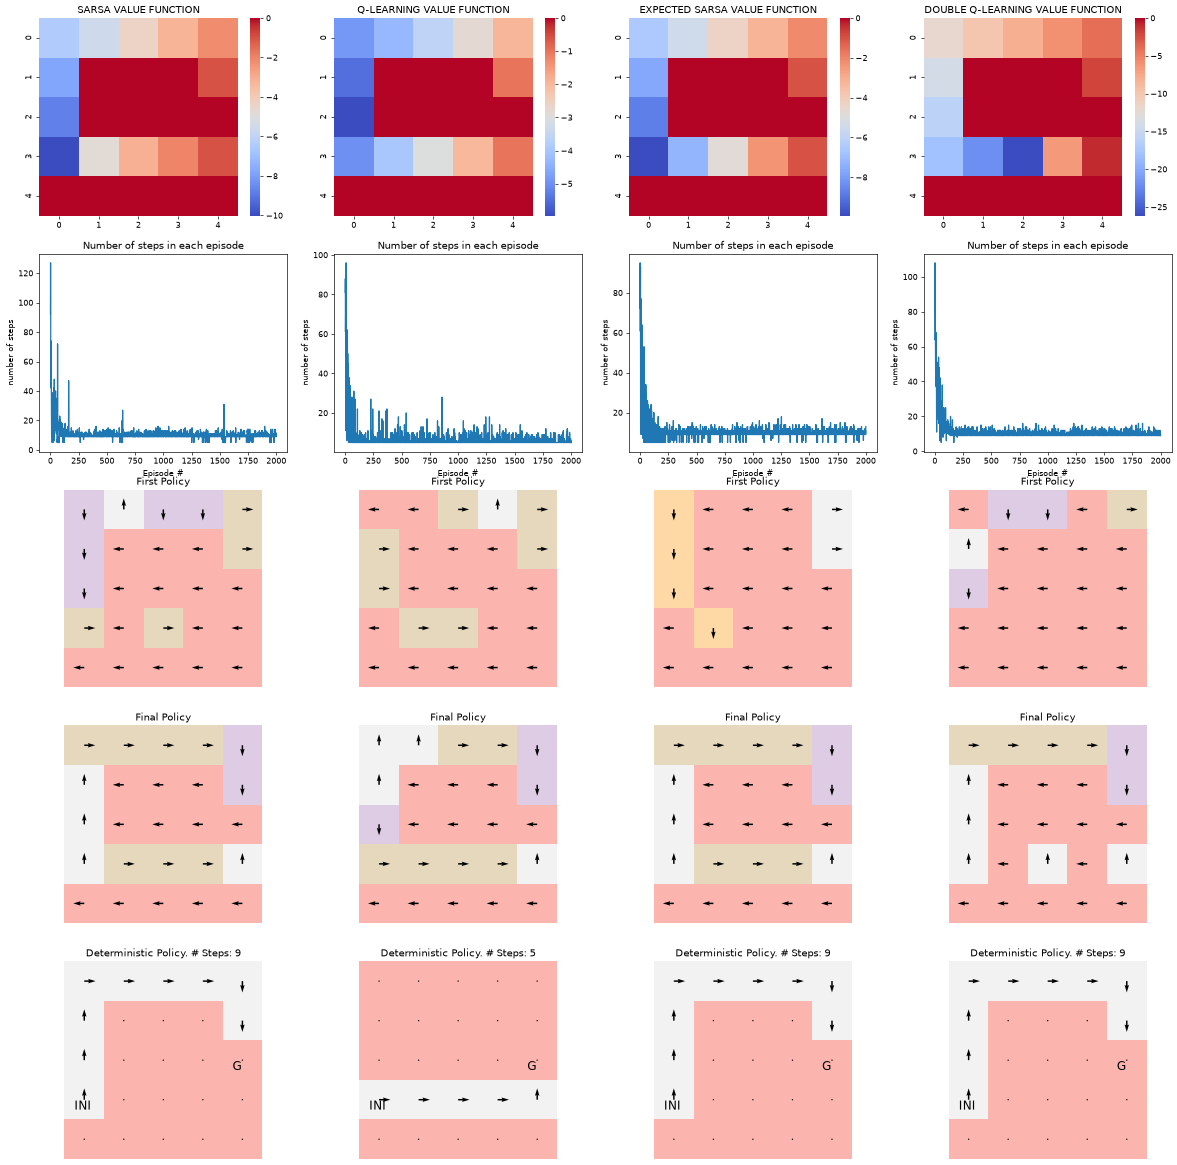

In [ ]:
general_plot(total_v_funs, total_counts, total_first_p, total_final_p, total_determ_p, total_steps, grid)

The test runs the $2000$ episodes without the stopping criterion.

SARSA and Expected SARSA learn the long path along the first row, with $9$ steps. Their targets follow the $\epsilon$-greedy policy. In the cells next to the cliff an exploratory action can give $-100$, so these cells get low values and the policy avoids them. Q-learning learns the short path next to the cliff, with $5$ steps. Its target uses $\max_a Q(S_{t+1},a)$, so it learns the values of the greedy policy, which never falls.

Q-learning obtains the path with the best return, $G(s_{ini}) = -5$ against $-9$, but it has the worst performance during training. It still explores with the $\epsilon$-greedy policy while it walks next to the cliff. It falls in $234$ of the $2000$ episodes and its average $G(s_{ini})$ is $-19.3$. SARSA and Expected SARSA fall in $76$ and $77$ episodes and their average is about $-14.7$.

Double Q-learning also learns the long path, although it is an off-policy method like Q-learning. Its value function is much lower than the other three in the cells next to the cliff. A possible reason is that its target $Q_2(S_{t+1}, \arg\max_a Q_1(S_{t+1},a))$ is never higher than $\max_a Q_2(S_{t+1},a)$, so it underestimates these cells.

In conclusion, the path of Q-learning is the best one if the agent follows the greedy policy after training. If the agent keeps exploring, the path of SARSA and Expected SARSA gives a better return.